# Lesson 11 - CWRU Envelope Analysis

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.io import loadmat
from scipy.stats import kurtosis
from scipy.signal import hilbert, butter, sosfiltfilt

In [3]:
# Define the data path
cwd = Path.cwd()

if (cwd / "data").exists():
    project_root = cwd
elif (cwd.parent / "data").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not find project data folder")

data_dir = (project_root / "data" / "cwru" / "raw")

print(data_dir)
list(data_dir.iterdir())

c:\Users\User\Documents\Projects\predictive-maintenance-system\data\cwru\raw


[WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/109.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/122.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/135.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/97.mat')]

In [4]:
# File Loader
def load_cwru_file(file_path, channel="DE_time"):
    data = loadmat(file_path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    signal_key = next(
        key
        for key in keys
        if channel in key
    )

    rpm_key = next(
        (
            key
            for key in keys
            if "RPM" in key
        ),
        None
    )

    signal = data[signal_key].squeeze()

    rpm = None
    if rpm_key is not None:
        rpm = float(
            np.asarray(
                data[rpm_key]
            ).squeeze()
        )

    return signal, rpm

In [5]:
# Load all four conditions
files = {
    "Normal": "97.mat",
    "Inner race": "109.mat",
    "Ball": "122.mat",
    "Outer race": "135.mat"
}

signals = {}
rpms = {}

for condition, filename in files.items():
    signal, rpm = load_cwru_file(data_dir / filename)
    signals[condition] = signal
    rpms[condition] = rpm

rpms

{'Normal': 1796.0, 'Inner race': 1796.0, 'Ball': 1796.0, 'Outer race': 1796.0}

In [6]:
# Add CWRU multipliers
CWRU_MULTIPLIERS = {
    "bpfi": 5.4152,
    "bpfo": 3.5848,
    "ftf": 0.39828,
    "rolling_element": 4.7135
}

In [7]:
# Function for calculating bearing frequencies
def calculate_bearing_frequencies(rpm):
    shaft_frequency = rpm / 60

    return {
        "shaft": shaft_frequency,
        "bpfi": CWRU_MULTIPLIERS["bpfi"] * shaft_frequency,
        "bpfo": CWRU_MULTIPLIERS["bpfo"] * shaft_frequency,
        "ftf": CWRU_MULTIPLIERS["ftf"] * shaft_frequency,
        "rolling_element": CWRU_MULTIPLIERS["rolling_element"] * shaft_frequency
    }

In [8]:
# Calculate using rpm from data
frequency_rows = []

for condition, rpm in rpms.items():
    fault_frequencies = calculate_bearing_frequencies(rpm)
    fault_frequencies["condition"] = condition
    fault_frequencies["rpm"] = rpm

    frequency_rows.append(fault_frequencies)

In [9]:
# Inspect recording lengths
sampling_rate = 48000

for condition, signal in signals.items():
    duration = len(signal) / sampling_rate

    print(
        f"{condition:12}"
        f"samples = {len(signal):8d} "
        f"duration = {duration:.2f} s "
        f"RPM = {rpms[condition]}"
    )

Normal      samples =   243938 duration = 5.08 s RPM = 1796.0
Inner race  samples =   243938 duration = 5.08 s RPM = 1796.0
Ball        samples =   244739 duration = 5.10 s RPM = 1796.0
Outer race  samples =   243538 duration = 5.07 s RPM = 1796.0


In [10]:
# Use 2 second vibration segment for a better frequency resolution
analysis_duration = 2.0
analysis_samples = int(sampling_rate * analysis_duration)

In [11]:
# Create analysis window
analysis_windows = {}

for condition, signal in signals.items():
    analysis_windows[condition] = signal[:analysis_samples]

In [12]:
# Use outer-race signal
condition = "Outer race"

signal = analysis_windows[condition]
rpm = rpms[condition]
fault_freqs = calculate_bearing_frequencies(rpm)
expected_bpfo = fault_freqs["bpfo"]

print(f"RPM: {rpm:.1f}")
print(f"Expected BPFO: {expected_bpfo:.2f} Hz")

RPM: 1796.0
Expected BPFO: 107.31 Hz


In [13]:
# See what Hilbert transform does
centered_signal = signal - np.mean(signal)
analytic_signal = hilbert(centered_signal)
envelope = np.abs(analytic_signal)

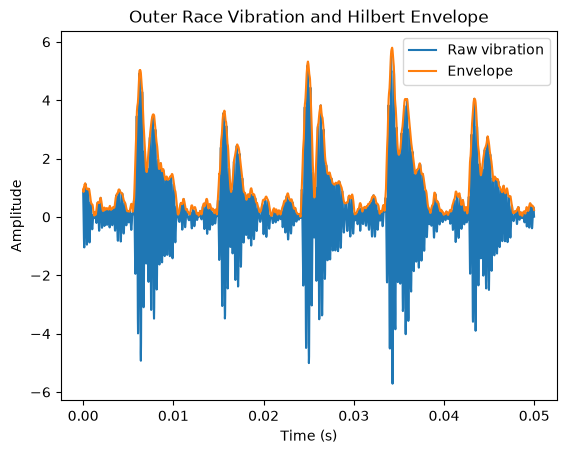

In [14]:
# Plot the raw signal and its envelope
time = np.arange(len(signal)) / sampling_rate
display_duration = 0.05
display_samples = int(display_duration * sampling_rate)

plt.plot(time[:display_samples], centered_signal[:display_samples], label="Raw vibration")
plt.plot(time[:display_samples], envelope[:display_samples], label="Envelope")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Outer Race Vibration and Hilbert Envelope")
plt.legend()
plt.show()

In [15]:
# Create envelope-spectrum function
def calculate_envelope_spectrum(signal, sampling_rate):
    analytic_signal = hilbert(signal)
    envelope = np.abs(analytic_signal)
    centered_envelope = envelope - np.mean(envelope)

    # Add a Hann window
    N = len(centered_envelope)
    window = np.hanning(N)
    windowed_envelope = centered_envelope * window
    coherent_gain = np.mean(window)

    # Fast Fourier Transform (FFT)
    fft_values = np.fft.rfft(windowed_envelope)
    frequencies = np.fft.rfftfreq(N, d=1 / sampling_rate)
    amplitudes = (2 / (N * coherent_gain)) * np.abs(fft_values)
    
    amplitudes[0] /= 2
    if N % 2 == 0:
        amplitudes[-1] /= 2

    return frequencies, amplitudes, envelope

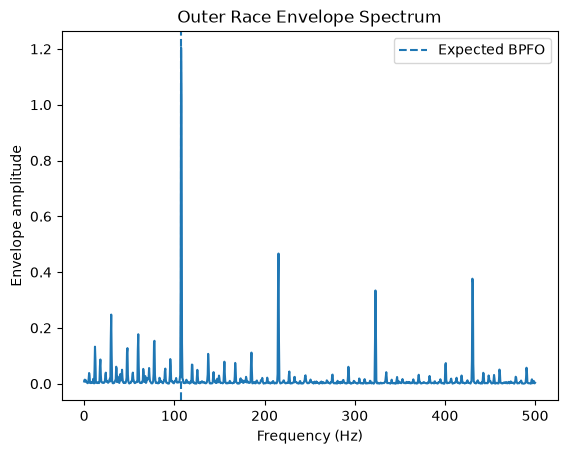

In [16]:
# Plot envelope spectrum
env_frequencies, env_amplitudes, envelope = calculate_envelope_spectrum(centered_signal, sampling_rate)

mask = env_frequencies <= 500
plt.plot(env_frequencies[mask], env_amplitudes[mask])

plt.axvline(expected_bpfo, linestyle="--", label="Expected BPFO")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Outer Race Envelope Spectrum")

plt.legend()
plt.show()

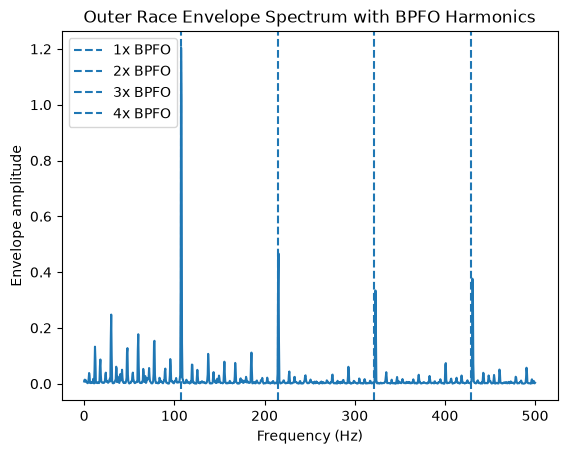

In [17]:
# Plot with BPFO harmonics
mask = env_frequencies <= 500
plt.plot(env_frequencies[mask], env_amplitudes[mask])

for harmonic in range(1, 5):
    target = harmonic * expected_bpfo
    plt.axvline(target, linestyle="--", label=f"{harmonic}x BPFO")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Outer Race Envelope Spectrum with BPFO Harmonics")

plt.legend()
plt.show()

In [18]:
# Search near the theoretical frequency
def find_peak_near(frequencies, amplitudes, target_frequency, search_width=5):
    # Find frequencies within target_frequency +- search_width
    mask = (
        frequencies >= target_frequency - search_width
    ) & (
        frequencies <= target_frequency + search_width
    )

    local_frequency = frequencies[mask]
    local_amplitude = amplitudes[mask]
    local_peak_index = np.argmax(local_amplitude)

    return local_frequency[local_peak_index], local_amplitude[local_peak_index]

In [19]:
# Find peak frequency and amplitude
for harmonic in range(1, 5):
    target = harmonic * expected_bpfo

    peak_frequency, peak_amplitude = find_peak_near(env_frequencies, env_amplitudes, target)
    difference = peak_frequency - target

    print(
        f"{harmonic}x BPFO | "
        f"expected = {target:.2f} Hz | "
        f"peak = {peak_frequency:.2f} Hz | "
        f"difference = {difference:.2f} Hz | "
        f"amplitude = {peak_amplitude:.6f}"
    )

1x BPFO | expected = 107.31 Hz | peak = 107.50 Hz | difference = 0.19 Hz | amplitude = 1.204461
2x BPFO | expected = 214.61 Hz | peak = 215.50 Hz | difference = 0.89 Hz | amplitude = 0.466585
3x BPFO | expected = 321.92 Hz | peak = 323.00 Hz | difference = 1.08 Hz | amplitude = 0.334166
4x BPFO | expected = 429.22 Hz | peak = 430.50 Hz | difference = 1.28 Hz | amplitude = 0.376443


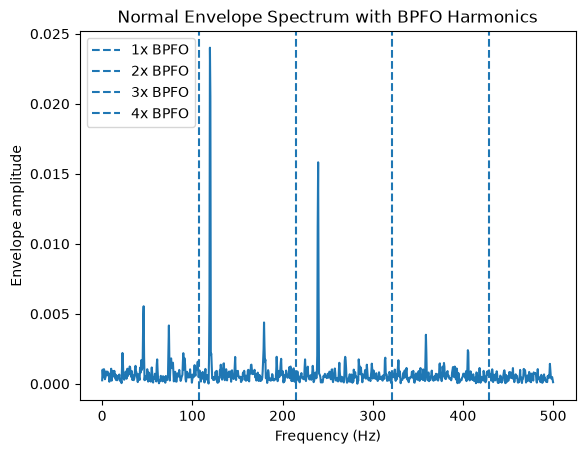

In [20]:
# Compare against normal
normal_signal = analysis_windows["Normal"]
centered_normal_signal = normal_signal - np.mean(normal_signal)
normal_env_freqs, normal_env_amps, _ = calculate_envelope_spectrum(centered_normal_signal, sampling_rate)

# Plot comparison
mask = normal_env_freqs <= 500
plt.plot(normal_env_freqs[mask], normal_env_amps[mask])

for harmonic in range(1, 5):
    target = harmonic * expected_bpfo
    plt.axvline(target, linestyle="--", label=f"{harmonic}x BPFO")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Normal Envelope Spectrum with BPFO Harmonics")

plt.legend()
plt.show()

In [21]:
# Apply zero-phase Butterworth bandpass filter
# Remove all frequencies below low_cut and above high_cut
def bandpass_filter(signal, sampling_rate, low_cut, high_cut, order=4):
    # Use second-order sections (output="sos"), more stable
    sos = butter(order, [low_cut, high_cut], btype="bandpass", fs=sampling_rate, output="sos")

    # Forward-backward filtering (avoid phase shift)
    filtered_signal = sosfiltfilt(sos, signal)

    return filtered_signal

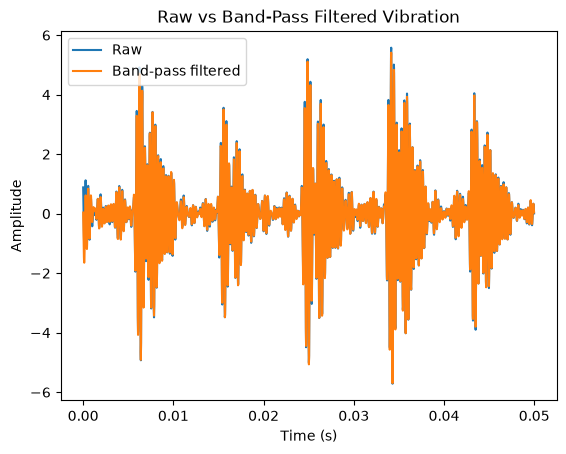

In [22]:
# Apply bandpass filter (500 - 5000 Hz is for experimental analysis)
filtered_signal = bandpass_filter(centered_signal, sampling_rate, 500, 5000)

# Plot before and after filtering
plt.plot(time[:display_samples], centered_signal[:display_samples], label="Raw")
plt.plot(time[:display_samples], filtered_signal[:display_samples], label="Band-pass filtered")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Raw vs Band-Pass Filtered Vibration")

plt.legend()
plt.show()

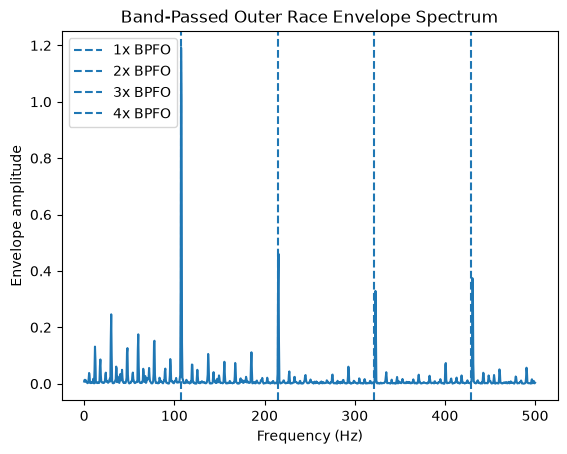

In [23]:
# Envelope the filtered signal
filtered_env_freqs, filtered_env_amps, filtered_envelope = (
    calculate_envelope_spectrum(filtered_signal, sampling_rate)
)

# Plot filtered envelope spectrum
mask = filtered_env_freqs <= 500
plt.plot(filtered_env_freqs[mask], filtered_env_amps[mask])

for harmonic in range(1, 5):
    target = harmonic * expected_bpfo
    plt.axvline(target, linestyle="--", label=f"{harmonic}x BPFO")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Band-Passed Outer Race Envelope Spectrum")

plt.legend()
plt.show()

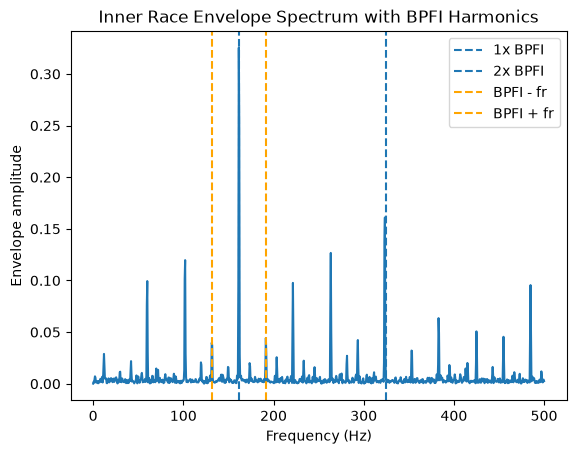

In [38]:
# For inner race
condition = "Inner race"
expected_bpfi = calculate_bearing_frequencies(rpms[condition])["bpfi"]

signal = analysis_windows[condition]
centered_signal = signal - np.mean(signal)
filtered_signal = bandpass_filter(centered_signal, sampling_rate, 500, 5000)
env_freqs, env_amps, _ = calculate_envelope_spectrum(filtered_signal, sampling_rate)

# Plot comparison
mask = env_freqs <= 500
plt.plot(env_freqs[mask], env_amps[mask])

for harmonic in range(1, 3):
    target = harmonic * expected_bpfi
    plt.axvline(target, linestyle="--", label=f"{harmonic}x BPFI")

# Add a vertical line at the sidebands (+- rotational frequency)
plt.axvline(expected_bpfi - rpms[condition] / 60, color='orange', linestyle="--", label="BPFI - fr")
plt.axvline(expected_bpfi + rpms[condition] / 60, color='orange', linestyle="--", label="BPFI + fr")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Inner Race Envelope Spectrum with BPFI Harmonics")

plt.legend()
plt.show()

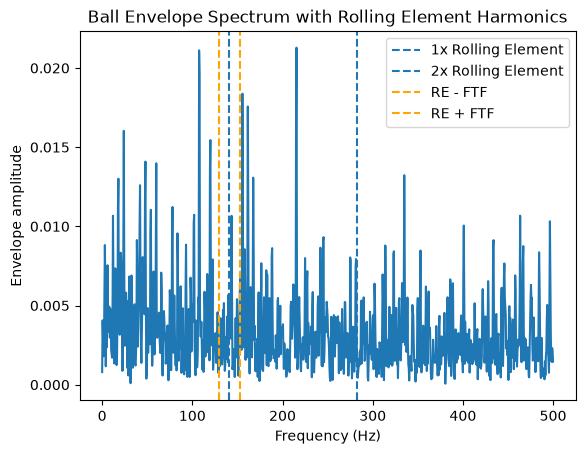

In [39]:
# For ball fault
condition = "Ball"
expected_rolling_element = calculate_bearing_frequencies(rpms[condition])["rolling_element"]
expected_ftf = calculate_bearing_frequencies(rpms[condition])["ftf"]

signal = analysis_windows[condition]
centered_signal = signal - np.mean(signal)
filtered_signal = bandpass_filter(centered_signal, sampling_rate, 500, 5000)
env_freqs, env_amps, _ = calculate_envelope_spectrum(filtered_signal, sampling_rate)

# Plot comparison
mask = env_freqs <= 500
plt.plot(env_freqs[mask], env_amps[mask])

for harmonic in range(1, 3):
    target = harmonic * expected_rolling_element
    plt.axvline(target, linestyle="--", label=f"{harmonic}x Rolling Element")

# Add a vertical line at the sidebands (+- rotational frequency)
plt.axvline(expected_rolling_element - expected_ftf, color='orange', linestyle="--", label="RE - FTF")
plt.axvline(expected_rolling_element + expected_ftf, color='orange', linestyle="--", label="RE + FTF")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Ball Envelope Spectrum with Rolling Element Harmonics")

plt.legend()
plt.show()

In [40]:
# Convert time-domain to frequency-domain using FFT
def calculate_fft(signal, sampling_rate):
    N = len(signal)
    centered_signal = (signal - np.mean(signal))

    # Use Hann window
    window = np.hanning(N)
    windowed_signal = (centered_signal * window)
    coherent_gain = np.mean(window)

    fft_values = np.fft.rfft(windowed_signal)
    frequencies = np.fft.rfftfreq(N, d=1 / sampling_rate)
    amplitudes = (2 / (N * coherent_gain)) * np.abs(fft_values)

    amplitudes[0] /= 2
    if N % 2 == 0:
        amplitudes[-1] /= 2

    return frequencies, amplitudes

In [ ]:
# Compare them
expected_faults = {
    "Inner race": "bpfi",
    "Ball": "rolling_element",
    "Outer race": "bpfo"
}
comparison_rows = []

for condition, fault in expected_faults.items():
    expected_fault_frequency = calculate_bearing_frequencies(rpms[condition])[fault]

    signal = analysis_windows[condition]
    centered_signal = signal - np.mean(signal)

    raw_freq, raw_amp = calculate_fft(centered_signal, sampling_rate)
    peak_freq, peak_amp = find_peak_near(raw_freq, raw_amp, expected_fault_frequency)
    
    env_freqs, env_amps, _ = calculate_envelope_spectrum(centered_signal, sampling_rate)
    env_peak_freq, env_peak_amp = find_peak_near(env_freqs, env_amps, expected_fault_frequency)

    filtered_signal = bandpass_filter(centered_signal, sampling_rate, 500, 5000)
    filt_env_freqs, filt_env_amps, _ = calculate_envelope_spectrum(filtered_signal, sampling_rate)    
    filt_peak_freq, filt_peak_amp = find_peak_near(
        filt_env_freqs, filt_env_amps, expected_fault_frequency
    )

    comparison_rows.append({
        "condition": condition,
        "expected": expected_fault_frequency,
        "raw_fft_amp": peak_amp,
        "full_env_amp": env_peak_amp,
        "filtered_env_amp": filt_peak_amp,
        "nearest_env_peak_freq": filt_peak_freq,
        "freq_diff": filt_peak_freq - expected_fault_frequency
    })

fault_comparison = pd.DataFrame(comparison_rows)

fault_comparison

,condition,expected,raw_fft_amp,full_env_amp,filtered_env_amp,nearest_env_peak_freq,freq_diff
0,Inner race,162.094987,0.019435,0.333664,0.325414,161.5,-0.594987
1,Ball,141.090767,0.000556,0.010338,0.010666,143.5,2.409233
2,Outer race,107.305013,0.001133,1.204461,1.191784,107.5,0.194987


Filtered peak amplitude for envelope analysis has a much higher value compared to raw FFT. Hence, it is easier to detect the faults when the peak is easier to observe. This shows that envelope analysis helps detect faults more obviously.